<a href="https://colab.research.google.com/github/kmiloperez-data/Proyecto-7-Explorando-drivers-de-comportamiento-en-NovaRetail-/blob/main/S8_Student_Version_Project_NovaRetail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [ ]:
# Importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


### Cargar Dataset

In [ ]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [ ]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`


La mayoría de estas variables presentan tipos de datos adecuados.  
La columna de edad se cargo como `float64`, "numero decimal", al imprimir las 5 primeras filas del dataset, se confirma que este formato se debe a que el archivo `CSV` la edad se ecuentra escrita con decimales, y pandas simplemente respeto el formato que se encontro en el archivo original.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.


In [ ]:
# Corregir el tipo de dato
df_copy= df.copy()
df_copy['edad'] = df_copy['edad'].astype(int)

In [ ]:
# verificar cambios
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
df_copy.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- `edad` — va de 18 a 75 años, con media (38.3) y mediana (38) casi iguales, así que el centro de la distribución es simétrico. El máximo (75) queda a unas 3.2 desviaciones estándar de la       media (DE = 11.5) y bastante por encima del percentil 75 (46), lo que sugiere pocos clientes de edad avanzada. La tabla no permite confirmar que la distribución sea “normal”.
- `nivel_ingreso` — media (30,020) y mediana (30,024) casi idénticas, pero el máximo (74,791) está a más de 4 desviaciones de la media (DE = 9,833) y es más del doble del percentil 75           (36,768). Hay una cola larga a la derecha con posibles valores atípicos, así que no puede describirse como una distribución sin valores extremos.
- `visitas_mes`— media 10.0 y mediana 10, con DE de 3.2. El máximo (25) está a casi 5 desviaciones de la media y muy por encima del percentil 75 (12). La mayoría de los clientes se concentra    entre 8 y 12 visitas, y unos pocos con tráfico muy alto forman una cola a la derecha.
- `compras_mes` — el mínimo y el percentil 25 son 0, es decir, al menos una cuarta parte de los clientes no compra en el mes. La mediana (1) es menor que la media (1.21), y el máximo (8) está   a más de 6 desviaciones de la media (DE = 1.1) frente a un percentil 75 de 2. Esto indica una distribución sesgada a la derecha, con pocos clientes de compra muy frecuente.
- `gasto_publicidad_dirigida` — media (20.1) y mediana (19.7) cercanas, con DE de 10.9. El máximo (75.5) está a más de 5 desviaciones de la media y es casi el triple del percentil 75 (27.3).    La mayoría de los clientes recibe una inversión moderada, pero hay una cola a la derecha de clientes con inversión muy alta, no una inversión “controlada”.
- `satisfaccion` — se mueve en la escala de 1 a 5, con media 3.6, mediana 3.6 y DE de 0.69. El percentil 25 (3.1) y el 75 (4.1) indican que la mitad central de los clientes califica entre 3.1    y 4.1. Por estar acotada por la escala, sus extremos son limitados; el mínimo (1) queda a casi 4 desviaciones por debajo de la media, lo que apunta a pocos clientes muy insatisfechos.
- `ingreso_anual` —el mínimo y el percentil 25 son 0, lo que sugiere clientes que no generan ingresos. La mediana (30.7) es menor que la media (36.6), y el máximo (244.7) está a más de 6        desviaciones de la media (DE = 34.5) y es más de cuatro veces el percentil 75 (58.2). Esto evidencia un sesgo a la derecha y posibles valores atípicos importantes para la interpretación de    Pearson.

#### Explorar variables binarias

In [ ]:
# Verificar que cada columna tenga únicamente dos valores posibles

columnas_a_revisar = ["miembro_premium", "abandono"]

for col in columnas_a_revisar:
    print(f"--- Distribución de la columna: {col} ---")
    print(df_copy[col].value_counts())
    print("\n" + "="*40 + "\n")

--- Distribución de la columna: miembro_premium ---
0    12911
1     2089
Name: miembro_premium, dtype: int64


--- Distribución de la columna: abandono ---
0    12739
1     2261
Name: abandono, dtype: int64




✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium` — Variable binaria sin valores inesperados. La gran mayoría de los clientes de NovaRetail+ durante 2024 son estándar (86%, 12.911 clientes), y los premium (codificados como 1) son el 14% restante (2.089 clientes). Hay un desbalance de clases a considerar.
- `abandono` — Variable binaria sin valores inesperados. La tasa de abandono general es del 15% (2.261 clientes), con 85% de clientes que permanecen. También hay desbalance de clases.

#### Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica
columnas_a_revisar = ["tipo_dispositivo", "region"]

for col in columnas_a_revisar:
    print(f"--- Valores únicos: {col} ---")
    print(df_copy[col].nunique())
    print("\n" + "="*40 + "\n")

--- Valores únicos: tipo_dispositivo ---
3


--- Valores únicos: region ---
4




In [ ]:
# Explorar variables categóricas y cómo se distribuyen
columnas_a_revisar = ["tipo_dispositivo", "region"]

for col in columnas_a_revisar:
    print(f"---  Distribución de la columna: {col} ---")
    print(df_copy[col].value_counts())
    print("\n" + "="*40 + "\n")

---  Distribución de la columna: tipo_dispositivo ---
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64


---  Distribución de la columna: region ---
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64




✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — la categoría  móvil es la dominante (9818), seguida de escritorio (3720) y tablet (1462).
- `region` - las cuatro regiones están bastante balanceadas, con norte liderando ligeramente (4395) y este con menos registros (3069).

### Supuestos

- El análisis se realiza utilizando todo el conjunto de datos disponible.
- Los datos han sido preparados bajo las siguientes decisiones metodológicas y de tipificación:
  - La variable edad se convirtió a tipo entero para un manejo numérico más preciso.
  - La columna id_cliente se excluye explícitamente de las correlaciones al tratarse de un identificador unívoco sin valor analítico predictivo.
  - Las variables binarias se tratan numéricamente como $0/1$ para permitir su inclusión en los cálculos estadísticos correspondientes.
  - Los valores en cero encontrados en compras_mes e ingreso_anual se conservan como datos válidos, representando a clientes que no registran compras o ingresos en el periodo.
- Se utilizan distintos coeficientes según el tipo de variable:
  - Pearson asume relaciones lineales entre variables numéricas.
  - Spearman evalúa relaciones monótonas y no requiere normalidad.
  - Punto biserial se usa para relaciones numérica–binaria.
  - Cramér (V) se usa para asociaciones entre variables categóricas.
    
**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

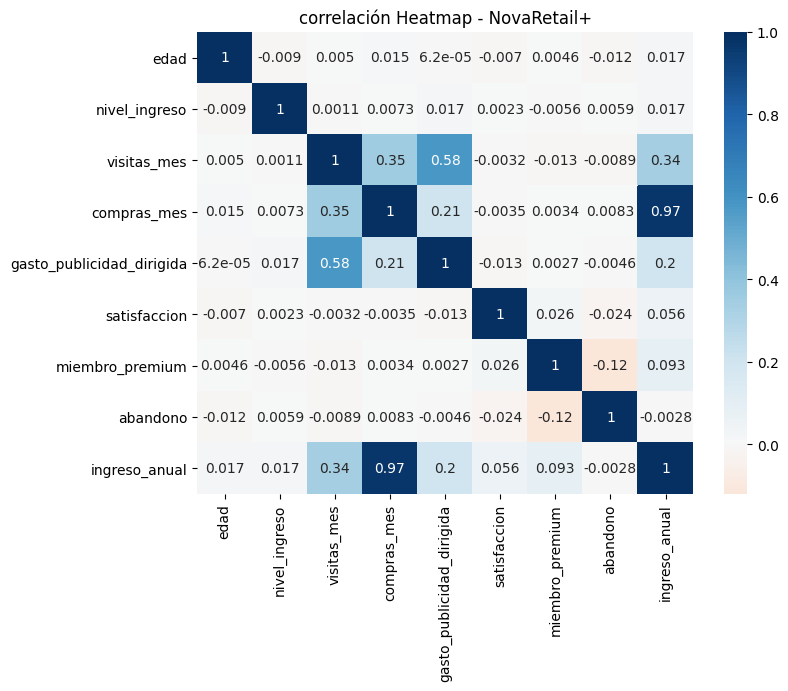

In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
corr= df_copy.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="RdBu", center=0)
plt.title('correlación Heatmap - NovaRetail+')
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves


Observaciones generales (Heatmap)  
- `Se observa`:
- Edad y satisfacción: sus coeficientes con el resto de variables son cercanos a 0 (en valor absoluto, menores a 0.06). Esto indica que no hay una asociación lineal relevante, aunque no se descarta que existan       relaciones no lineales.
- visitas_mes y gasto_publicidad_dirigida: presentan una correlación positiva moderada (0.58), es decir, tienden a aumentar juntas. El mapa describe esta asociación, pero no permite concluir que la publicidad       genere las visitas. Podrían influir otros factores, como campañas o temporadas.
- abandono: presenta coeficientes muy bajos con todas las variables. La asociación más fuerte es con miembro_premium (-0.12), una relación negativa débil: los miembros premium tienden a abandonar algo menos.        Ninguna métrica individual explica el abandono de forma lineal, por lo que conviene analizarlo con técnicas que combinen variables.


Observaciones respecto a `ingreso_anual`  
- `Presenta`:
- Asociación casi total con compras_mes (0.97): las dos variables se mueven casi al unísono. Probablemente ingreso_anual se derive de las compras o esté muy determinado por ellas, así que no deben tratarse como     variables independientes. Para el negocio, esto significa que aportan casi la misma información. Usar ambas en un modelo generaría redundancia (multicolinealidad), y conviene verificar cómo se construye           ingreso_anual.
- Asociación débil a moderada con visitas_mes (0.34): los clientes con mayor ingreso tienden a visitar más la plataforma, aunque la relación no es fuerte.
- Asociación débil con gasto_publicidad_dirigida (0.20): la relación lineal es baja. Esto sugiere que la pauta, por sí sola, se asocia poco con el ingreso, aunque no permite concluir sobre su efecto.
- Asociación casi nula con nivel_ingreso (0.017), satisfaccion (0.056) y edad (0.017): el nivel de ingreso estimado de un cliente casi no se asocia con el ingreso que realmente genera. Para el negocio, segmentar    por nivel_ingreso, edad o satisfacción no sirve para identificar a los clientes de mayor valor. El comportamiento transaccional es un mejor indicador.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.
  - Se determina no incluir una matriz de gráficos de dispersión (scatterplot) general para todo el conjunto de datos, dado que el objetivo central del análisis se encuentra acotado y enfocado específicamente en la métrica de ingreso_anual. El      análisis previo de correlación (heatmap) demostró que la gran mayoría de las variables poseen una relación lineal nula o irrelevante con los ingresos, concentrando los inductores clave de valor únicamente en tres variables (compras_mes,         visitas_mes y gasto_publicidad_dirigida). En consecuencia, generar un gráfico de dispersión masivo con todas las dimensiones del dataset produciría ruido visual redundante y sin valor analítico; por lo que metodológicamente es más eficiente     y limpio orientar los esfuerzos visuales de forma exclusiva hacia las variables que impactan directamente el foco de estudio.

### Scatterplot para pares clave

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes


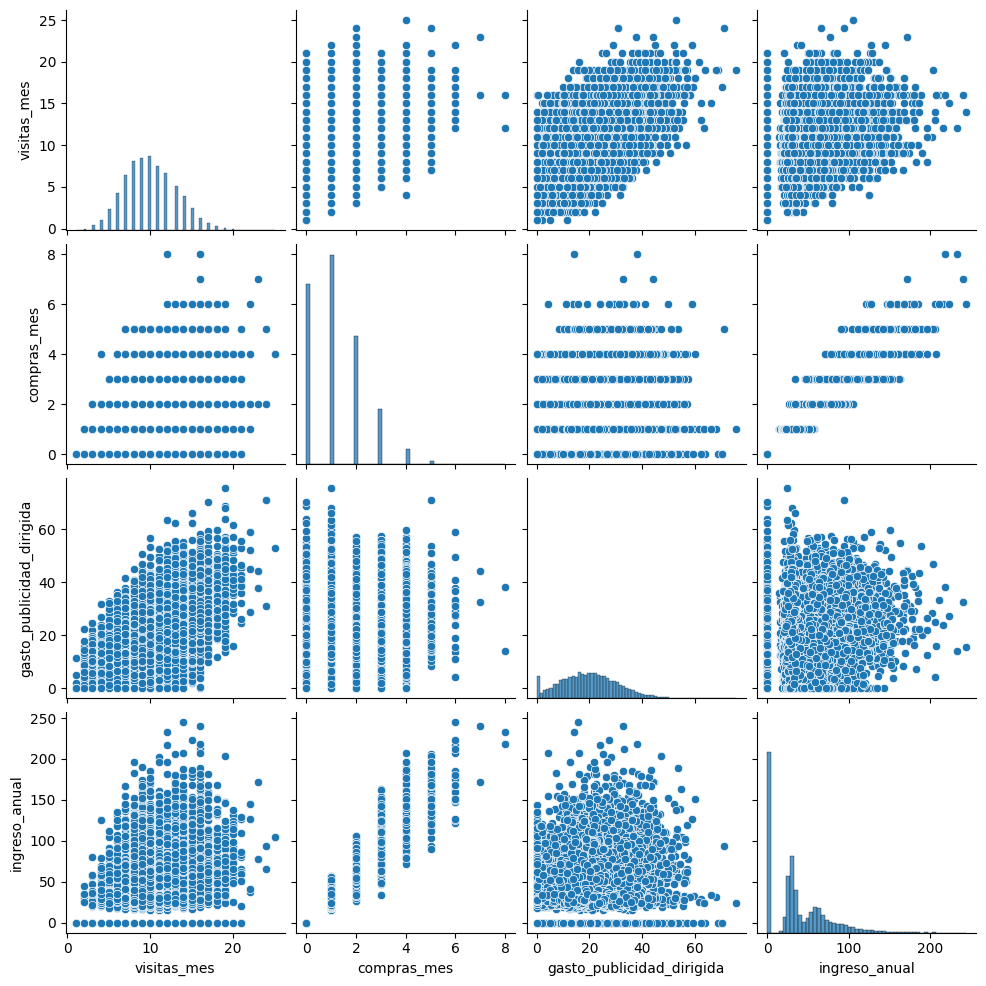

In [ ]:
sns.pairplot(df_copy[['visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida', 'ingreso_anual']])
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)

**visitas_mes vs compras_mes (r ≈ 0.35)**

Dirección: positiva y débil. Los clientes con más compras tienden a tener más visitas, pero a cualquier nivel de visitas hay clientes con pocas o ninguna compra.
Dispersión: alta. Como compras_mes toma pocos valores enteros (0 a 8), los puntos forman columnas verticales. Dentro de cada columna las visitas cubren un rango amplio (con 0 compras, por ejemplo, van de ~1 a ~21 visitas). Además, los puntos se superponen y no muestran cuántos clientes hay en cada zona. La mayoría se concentra en 0 a 2 compras.
Outliers: los pocos puntos con 6 a 8 compras se ven aislados. Más que atípicos, son la cola de una distribución concentrada en valores bajos. Conviene confirmarlo con un boxplot.
Colinealidad: baja. Con r ≈ 0.35 las dos predictoras no se solapan lo suficiente para ser redundantes.

**visitas_mes vs gasto_publicidad_dirigida (r ≈ 0.58)**

Dirección: positiva. Ambas variables tienden a aumentar juntas. El gráfico no permite decir que la inversión publicitaria genera las visitas, ni descartar que un tercer factor explique las dos.
Dispersión: alta. La nube es ancha y, para cualquier nivel de gasto, las visitas abarcan un rango grande (con gasto ≈ 20, van de ~2 a ~19). Esto es consistente con una correlación moderada.
Outliers: hay pocos puntos aislados en los extremos (gasto > 65 o visitas ≥ 24), sin distorsionar la tendencia general.
Colinealidad: moderada. Es el par de predictoras con mayor solapamiento, pero r ≈ 0.58 no indica redundancia total. Conviene vigilarlo si ambas entran en un mismo modelo.

**compras_mes vs gasto_publicidad_dirigida (r ≈ 0.21)**

Dirección: positiva muy débil, casi imperceptible.
Dispersión: alta. En cada columna de compras, el gasto cubre casi todo el rango de 0 a 60.
Outliers: se ven algunos puntos con gasto cercano a 70 y 0 o 1 compras, y pocos puntos con 7 u 8 compras.
Colinealidad: baja. La inversión publicitaria se asocia poco con las compras.

**compras_mes vs ingreso_anual (r ≈ 0.97)**

Dirección: positiva y fuerte. El patrón es escalonado y casi lineal: a más compras, mayor ingreso. Los clientes con 0 compras aparecen con ingreso 0.
Dispersión: baja dentro de cada nivel de compras, aunque se abre un poco hacia valores altos (forma de abanico).
Outliers: no se observan puntos alejados de la tendencia. Los más altos (6 a 8 compras, ingreso ~220 a 245) siguen la misma línea.
Redundancia: las dos variables casi miden lo mismo. Usarlas juntas como predictoras aportaría poca información adicional, y conviene revisar cómo se calcula ingreso_anual.

**visitas_mes vs ingreso_anual (r ≈ 0.34)**

Dirección: positiva y débil.
Dispersión: alta. Con el mismo número de visitas hay ingresos desde 0 hasta más de 150.
Outliers: algunos clientes con ingreso superior a 150 se separan de la masa principal. Aparece además una banda en ingreso_anual = 0 a todos los niveles de visitas, probablemente clientes sin compras.
Colinealidad: baja. Las visitas aportan información distinta a la del ingreso.

**gasto_publicidad_dirigida vs ingreso_anual (r ≈ 0.20)**

Dirección: positiva muy débil. La nube no muestra una forma clara.
Dispersión: alta. El ingreso varía ampliamente en todo el rango de gasto.
Outliers: hay pocos clientes con ingresos altos (>150) y también la banda en 0.
Colinealidad: baja.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes
pearson_corr = df_copy['compras_mes'].corr(df_copy['ingreso_anual'],method='pearson')
spearman_corr = df_copy['compras_mes'].corr(df_copy['ingreso_anual'],method='spearman')
print('Pearson=', pearson_corr)
print('Spearman=', spearman_corr)

Pearson= 0.9671485435708564
Spearman= 0.967482492032673


In [ ]:
# Calcular correlación entre variables relevantes
pearson_corr = df_copy['visitas_mes'].corr(df_copy['ingreso_anual'],method='pearson')
spearman_corr = df_copy['visitas_mes'].corr(df_copy['ingreso_anual'],method='spearman')
print('Pearson=', pearson_corr)
print('Spearman=', spearman_corr)

Pearson= 0.3371466432498745
Spearman= 0.32095369737696483


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

**compras_mes vs ingreso_anual**
- Correlación y dirección: positiva y muy fuerte, con Pearson (0.97) y Spearman (0.97) prácticamente idénticos. Los clientes con más compras mensuales tienden a registrar un mayor ingreso       anual. Que ambos coeficientes coincidan sugiere una relación monótona consistente, no distorsionada por valores atípicos, lo que respalda lo observado en el heatmap y en el scatterplot.
- Magnitud y colinealidad: magnitud muy alta. Las dos variables se mueven casi al unísono y aportan información muy parecida, por lo que no deben tratarse como independientes. Si ambas          entraran como predictoras en un mismo modelo, habría riesgo de redundancia (colinealidad). Probablemente ingreso_anual se construya a partir de las compras, algo que conviene verificar.

**visitas_mes vs ingreso_anual**
- Correlación y dirección: positiva y débil a moderada, con Pearson (0.34) y Spearman (0.32) similares. Los clientes con más visitas mensuales tienden a presentar un ingreso anual algo mayor,   aunque la asociación es limitada. La cercanía entre ambos coeficientes indica una relación monótona consistente.
- Magnitud y colinealidad: baja a moderada. Las visitas aportan información distinta a la de ingreso_anual, por lo que no hay un problema de colinealidad. Esta asociación es mucho menor que     la de compras_mes, así que las visitas, por sí solas, se relacionan de forma limitada con el ingreso.

### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr
columnas_a_revisar = ["miembro_premium", "abandono"]

for col in columnas_a_revisar:
    pb,_ = pointbiserialr(df_copy['ingreso_anual'], df_copy[col])
    print(f"--- Punto-biserial : {col} {pb:.3f}")
    print("\n" + "="*40 + "\n")

--- Punto-biserial : miembro_premium 0.093


--- Punto-biserial : abandono -0.003




✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**miembro_premium vs ingreso_anual**
- Relación y dirección: positiva muy débil (r_pb = 0.093). Los miembros premium tienden a presentar un ingreso anual ligeramente mayor que los clientes no premium, pero la diferencia es         pequeña.
- Magnitud: baja. La membresía premium, por sí sola, se asocia con muy poca de la variación en el ingreso anual, así que no es un factor diferenciador fuerte entre ambos segmentos. Este         resultado indica una asociación y no permite afirmar que la membresía genere más ingreso.
  
**abandono vs ingreso_anual**
- Relación y dirección: negativa prácticamente nula (r_pb = -0.003). El ingreso anual de los clientes que abandonaron es casi igual al de quienes permanecen.
- Magnitud: nula. Sugiere que el ingreso generado no ayuda a distinguir a los clientes que abandonan de los que se quedan, y que la deserción ocurre de forma transversal a distintos niveles     de ingreso.

### V de Cramér

In [ ]:
# Función para calcular V de Cramér
def cramer_v(df_copy, col1, col2):
    tabla = pd.crosstab(df_copy[col1], df_copy[col2])
    chi2, p, dof, expected = chi2_contingency(tabla)
    n = tabla.sum().sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

In [ ]:
# Aplicar V de Cramér en variables relevantes
from scipy import stats
from scipy.stats import chi2_contingency, pointbiserialr
pares = [
    ('region', 'tipo_dispositivo'),
    ('region', 'miembro_premium'),
    ('tipo_dispositivo', 'miembro_premium'),
    ('region', 'abandono'),
    ('tipo_dispositivo', 'abandono'),
    ('miembro_premium', 'abandono'),
]

resultados = pd.DataFrame(
    [{'par': f'{a} vs {b}', 'V_Cramer': round(cramer_v(df_copy, a, b), 4)} for a, b in pares]
)
print(resultados)

                                   par  V_Cramer
0           region vs tipo_dispositivo    0.0124
1            region vs miembro_premium    0.0126
2  tipo_dispositivo vs miembro_premium    0.0197
3                   region vs abandono    0.0154
4         tipo_dispositivo vs abandono    0.0072
5          miembro_premium vs abandono    0.1202


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves


Observaciones V de Cramér: Los coeficientes calculados entre las variables categóricas son muy bajos en la mayoría de los pares, lo que describe una asociación muy débil o prácticamente nula:

 - Entre variables de segmentación (region vs tipo_dispositivo: 0.012; region vs miembro_premium: 0.013; tipo_dispositivo vs miembro_premium: 0.020): no se observa evidencia de asociación        entre ellas.
 - Frente a abandono: region (0.015) y tipo_dispositivo (0.007) muestran una asociación prácticamente nula. miembro_premium vs abandono (0.120) es el valor más alto de la tabla y sugiere una     asociación débil, consistente con la correlación negativa de -0.12 que aparece en el heatmap: los miembros premium tienden a abandonar algo menos.

La V de Cramér mide la fuerza de una asociación, no su significancia, y aquí no se calcularon valores p. Por eso estos resultados no permiten afirmar que las variables sean independientes, solo que no se observa evidencia de una asociación relevante entre ellas.

Relación con la pregunta principal: como region y tipo_dispositivo casi no se asocian con miembro_premium ni con abandono, es poco probable que actúen como variables de confusión fuertes en las relaciones con ingreso_anual. Esto debe confirmarse revisando directamente su relación con ingreso_anual, por ejemplo comparando el ingreso promedio por región y por dispositivo.


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1 — compras_mes e ingreso_anual se mueven casi al unísono, probablemente por cómo se construye el ingreso

**Evidencia visual:** pairplot y scatterplot de compras_mes vs ingreso_anual, que muestran un patrón escalonado y casi lineal: a más compras, mayor ingreso, con baja dispersión dentro de cada   nivel de compras. Los clientes con 0 compras aparecen con ingreso anual 0. El mapa de calor (heatmap) muestra la misma relación (0.97).  
**Evidencia numérica:** Pearson = 0.967 y Spearman = 0.967 entre compras_mes e ingreso_anual. Que ambos coincidan indica una relación monótona consistente, no distorsionada por valores          atípicos.

**Interpretación** los clientes con más compras mensuales tienden a registrar un mayor ingreso anual, con una asociación muy fuerte. Sin embargo, esta cifra debe leerse con cautela: los         clientes con cero compras tienen ingreso cero, y la relación es casi perfecta, lo que sugiere que ingreso_anual podría derivarse de las compras (por ejemplo, compras por valor de ticket) y    no ser una variable independiente. En ese caso, el 0.97 reflejaría cómo se construye la variable más que un hallazgo sobre el comportamiento de los clientes.

**No podemos afirmar**
 - Que el aumento de las compras cause un mayor ingreso, ni que ingreso_anual sea una medida independiente de compras_mes.
 - Que el ingreso dependa solo del número de transacciones, ya que no se analizó el ticket promedio.
 - Que esta relación aporte información nueva sobre el comportamiento del cliente sin antes verificar cómo se calcula ingreso_anual.
Posible correlación engañosa: si ingreso_anual se calcula como compras × valor de ticket, la correlación es en parte mecánica. Para verificarlo, hay que revisar la documentación del dataset o comprobar si ingreso_anual / compras_mes (ticket implícito) es estable o varía mucho entre clientes.
**Implicación de negocio**incentivar la frecuencia de compra sigue siendo una línea razonable, pero no debe presentarse como la palanca principal sin evidencia adicional. Como compras_mes e ingreso_anual aportan casi la misma información, para explicar o predecir el valor del cliente conviene analizar otros factores (ticket promedio, membresía, visitas) y no usar ambas variables juntas como predictoras.


### Hallazgo 2 — visitas_mes y gasto_publicidad_dirigida se asocian débilmente con ingreso_anual, y la asociación con las visitas es la más marcada
**Evidencia visual:** en los paneles visitas_mes vs ingreso_anual y gasto_publicidad_dirigida vs ingreso_anual del pairplot, las nubes de puntos son anchas. Con el mismo número de visitas (o el mismo nivel de gasto) el ingreso anual abarca desde 0 hasta más de 150. Se ve además una banda de clientes con ingreso 0 a todos los niveles de visitas y de gasto. En el panel de visitas se insinúa una ligera inclinación ascendente; en el de gasto la nube casi no muestra forma. Estas lecturas están hechas a ojo.
**Evidencia numérica:**
- visitas_mes vs ingreso_anual: Pearson = 0.337 y Spearman = 0.321 (calculados en la sección 4.1). Asociación positiva débil a moderada, y ambos coeficientes coinciden.
- gasto_publicidad_dirigida vs ingreso_anual: r = 0.20, tomado del mapa de calor (Pearson). Asociación positiva débil. No se calculó Spearman para este par.

**Interpretación** los clientes con más visitas mensuales tienden a presentar un ingreso anual algo mayor, así que las visitas pueden verse como una señal modesta del valor del cliente. Aun así, la asociación es limitada: con el mismo número de visitas hay clientes con ingresos muy distintos, incluidos clientes con ingreso 0. El gasto en publicidad dirigida se asocia todavía menos con el ingreso (0.20 frente a 0.34), de modo que, por sí solo, dice poco sobre cuánto ingreso genera un cliente.


**No podemos afirmar**
  - Que las visitas causen un mayor ingreso: la asociación es débil y no controla otros factores, como si el cliente ya compra o qué tan activo es en general.
  - Que la publicidad genere ingreso, ni que su efecto sea nulo. Una correlación no permite concluir sobre el efecto, y el gasto se asigna por usuario. No sabemos a quiénes se dirigieron los      anuncios, y es posible que se dirigieran a clientes que ya visitan más o que ya tienen más probabilidad de comprar.
  - Que estas relaciones se mantengan en todos los segmentos, porque el análisis es bivariado.
  - Que la banda de clientes con ingreso 0 corresponda a un único perfil. Es probable que sean clientes sin compras, pero no se verificó.

**Implicación de negocio** las visitas pueden usarse como un indicador complementario del valor del cliente, pero no como un predictor fuerte por sí solas. Con esta evidencia no es posible justificar un aumento ni un recorte del presupuesto de publicidad dirigida. Para medir su efecto real habría que comparar grupos con distinta inversión o hacer una prueba controlada, y revisar a quién se dirigió la pauta. Mientras tanto, el comportamiento de compra sigue siendo el indicador más cercano al ingreso, con la cautela del Hallazgo 1.


## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**: Completa el siguiente bloque.   
Modifica según creas necesario.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### **Limitaciones**
- Correlación ≠ causalidad: Los coeficientes analizados demuestran asociaciones estadísticas y tendencias lineales, pero no prueban una relación de causa y efecto directa entre las variables.
- Posible correlación por construcción (ingreso_anual y compras_mes): el 0.97 probablemente refleja lo estrechamente vinculadas que están ambas variables por cómo se calcula el ingreso (los     clientes con cero compras tienen ingreso cero), y no necesariamente un hallazgo sobre el comportamiento. Esto limita su valor como evidencia independiente.
- Alcance de Pearson y Spearman: solo capturan relaciones lineales y monótonas. Pueden pasar por alto patrones no lineales o efectos que dependan de combinaciones de variables.
- Desbalance de clases: los miembros estándar son cerca del 86% de la base, y el abandono también es una clase minoritaria. Esto hace menos estables los coeficientes con miembro_premium y       abandono, y dificulta modelar el abandono.
- Variables sin relación con ingreso_anual: edad, satisfacción, nivel de ingreso, región y tipo de dispositivo mostraron asociaciones prácticamente nulas con ingreso_anual, y las dos últimas    solo se evaluaron entre sí y con abandono. No se probaron frente a ingreso_anual con una medida de asociación adecuada (por ejemplo, comparando promedios por grupo), por lo que no podemos     descartar su papel como variables de confusión.
- Alcance temporal estático: el análisis usa un conjunto de datos transversal del período 2024, sin series temporales que permitan evaluar la evolución ni la estacionalidad del comportamiento.

### **Próximos pasos**

**Paso 1: Verificar la construcción de ingreso_anual (derivado de la asociación más fuerte)**

- Revisar la documentación del dataset o calcular el ticket implícito (ingreso_anual / compras_mes) para determinar si el 0.97 es un hallazgo real o un resultado mecánico. De esto depende       cómo interpretar todo lo demás.
- Si el ingreso se compone de compras por valor de ticket, analizar por separado la frecuencia de compra y el ticket promedio como palancas de valor.

**Paso 2: Probar segmentación adicional frente a ingreso_anual**

- Comparar el ingreso por tipo de dispositivo y región, para confirmar si actúan o no como variables de confusión.
- Profundizar en el perfil del segmento estándar (86% de la base) para diseñar campañas focalizadas de conversión hacia membresías premium. Se justifica porque miembro_premium mostró una        asociación débil pero positiva con el ingreso (0.093).

**Paso 3: Modelar el abandono, con cautela**

- Desarrollar modelos supervisados (regresión logística o árboles de decisión) para estimar la probabilidad de abandono. Se justifica porque el abandono es una preocupación de negocio, aunque   el heatmap mostró casi ninguna relación lineal con el ingreso (-0.003): esto sugiere que el ingreso no basta para identificar a quienes se van, y que hacen falta modelos que combinen
  variables. Su asociación más alta fue con miembro_premium (V de Cramér = 0.12), y habrá que manejar el desbalance de clases.

**Paso 4: Evaluar el retorno de la publicidad dirigida**

- Medir el ROI de las campañas de gasto_publicidad_dirigida frente al valor de vida del cliente (LTV), idealmente con una comparación entre grupos o una prueba controlada, ya que las            asociaciones actuales con visitas e ingreso son débiles y no permiten concluir sobre su efecto.